In [1]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks.python import BaseOptions, vision
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

torch.set_num_threads(4)
torch.manual_seed(42)
np.random.seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
data_dir = '../../data/raw/hagrid/hagrid-sample-30k-384p/'
cache = '../../data/raw/hagrid/landmarks.npz'
os.makedirs('../../results/gesture', exist_ok=True)

print('Dataset: HaGRID 30k sample - https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p')
print('Hand points: MediaPipe Hand Landmarker - https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker')
print('Device:', torch.cuda.get_device_name(0) if device == 'cuda' else 'cpu')

Dataset: HaGRID 30k sample - https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p
Hand points: MediaPipe Hand Landmarker - https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker
Device: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
print('Loading the HaGRID annotations')
df = pd.read_parquet(data_dir + 'annotations_df.parquet')
files = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(data_dir + 'hagrid_30k/*/*.jpg')}
print('Images:', len(df), '| People:', df['user_id'].nunique())
print(df['labels'].explode().value_counts())

Loading the HaGRID annotations


Images: 31833 | People: 7973
labels
no_gesture         7052
two_up             1855
mute               1811
four               1805
stop_inverted      1803
dislike            1783
one                1778
palm               1770
peace              1769
two_up_inverted    1765
call               1763
three              1751
ok                 1750
stop               1748
peace_inverted     1742
three2             1737
rock               1736
fist               1734
like               1732
Name: count, dtype: int64


In [3]:
print('Finding the 21 points of every labelled hand with MediaPipe (saved after the first run)')
if os.path.exists(cache):
    saved = np.load(cache)
    points, labels, users = saved['points'], saved['labels'], saved['users']
else:
    landmarker = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(base_options=BaseOptions(model_asset_path='hand_landmarker.task'), num_hands=2))
    points, labels, users = [], [], []
    for image_id, row in df.iterrows():
        image = mp.Image.create_from_file(files[image_id])
        w, h = image.width, image.height
        for hand in landmarker.detect(image).hand_landmarks:
            p = np.array([[point.x * w, point.y * h, point.z * w] for point in hand])
            cx, cy = p[:, 0].mean() / w, p[:, 1].mean() / h
            for (bx, by, bw, bh), label in zip(row['bboxes'], row['labels']):
                if bx <= cx <= bx + bw and by <= cy <= by + bh:
                    points.append(p)
                    labels.append(label)
                    users.append(row['user_id'])
                    break
    points, labels, users = np.array(points, dtype=np.float32), np.array(labels), np.array(users)
    np.savez(cache, points=points, labels=labels, users=users)
print('Hands with points:', len(points))
print(pd.Series(labels).value_counts())

Finding the 21 points of every labelled hand with MediaPipe (saved after the first run)
Hands with points: 33240
no_gesture         4897
two_up             1676
three2             1658
four               1654
palm               1652
ok                 1615
stop               1596
peace_inverted     1593
stop_inverted      1590
peace              1576
three              1576
call               1575
one                1547
rock               1527
fist               1525
mute               1519
two_up_inverted    1515
dislike            1477
like               1472
Name: count, dtype: int64


In [4]:
print('Normalising: wrist at (0, 0), hand scaled to size 1, so position and distance from the camera do not matter')
def normalise(p):
    p = p - p[:, :1]
    return p / np.linalg.norm(p[:, :, :2], axis=2).max(axis=1)[:, None, None]

classes = [str(c) for c in sorted(set(labels))]
X = torch.tensor(normalise(points)).float()
y = torch.tensor([classes.index(label) for label in labels])
train_idx, rest = next(GroupShuffleSplit(1, test_size=0.3, random_state=42).split(X, y, users))
val_part, test_part = next(GroupShuffleSplit(1, test_size=0.5, random_state=42).split(rest, groups=users[rest]))
val_idx, test_idx = rest[val_part], rest[test_part]
print('Split by person (nobody is in two sets): train', len(train_idx), '| validation', len(val_idx), '| test', len(test_idx))
print('Classes:', classes)

Normalising: wrist at (0, 0), hand scaled to size 1, so position and distance from the camera do not matter


Split by person (nobody is in two sets): train

 22880 | validation 4978 | test 5382
Classes: ['call', 'dislike', 'fist', 'four', 'like', 'mute', 'no_gesture', 'ok', 'one', 'palm', 'peace', 'peace_inverted', 'rock', 'stop', 'stop_inverted', 'three', 'three2', 'two_up', 'two_up_inverted']


In [5]:
print('Model 1: logistic regression on the 63 point coordinates')
logreg = LogisticRegression(max_iter=3000).fit(X[train_idx].flatten(1), y[train_idx])
print('Validation accuracy:', round(accuracy_score(y[val_idx], logreg.predict(X[val_idx].flatten(1))), 4))

Model 1: logistic regression on the 63 point coordinates


Validation accuracy: 0.8839


In [6]:
print('Model 2: small neural network (MLP), trained with random mirror, rotation (±15°) and scale of the hand')
class GestureMLP(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(),
                                 nn.Linear(63, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
                                 nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
                                 nn.Linear(128, n_classes))

    def forward(self, x):
        return self.net(x)

def augment(x):
    n = len(x)
    flip = torch.where(torch.rand(n, 1, device=x.device) < 0.5, -1.0, 1.0)
    angle = (torch.rand(n, 1, device=x.device) - 0.5) * np.radians(30)
    scale = 0.9 + 0.2 * torch.rand(n, 1, device=x.device)
    px, py = x[:, :, 0] * flip, x[:, :, 1]
    return torch.stack([(px * torch.cos(angle) - py * torch.sin(angle)) * scale,
                        (px * torch.sin(angle) + py * torch.cos(angle)) * scale,
                        x[:, :, 2] * scale], dim=2)

mlp = GestureMLP(len(classes)).to(device)
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
X_train, y_train, X_val = X[train_idx].to(device), y[train_idx].to(device), X[val_idx].to(device)
history, best = [], 0
for epoch in range(60):
    mlp.train()
    order = torch.randperm(len(X_train), device=device)
    for i in range(0, len(order), 256):
        idx = order[i:i + 256]
        loss = loss_fn(mlp(augment(X_train[idx])), y_train[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    mlp.eval()
    with torch.no_grad():
        val_acc = accuracy_score(y[val_idx], mlp(X_val).argmax(1).cpu())
    history.append(val_acc)
    if val_acc > best:
        best, best_state = val_acc, {k: v.clone() for k, v in mlp.state_dict().items()}
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch + 1}/60  validation accuracy {val_acc:.4f}')
mlp.load_state_dict(best_state)
mlp.eval()
print('Best validation accuracy:', round(best, 4))

Model 2: small neural network (MLP), trained with random mirror, rotation (±15°) and scale of the hand


Epoch 10/60  validation accuracy 0.9755


Epoch 20/60  validation accuracy 0.9779


Epoch 30/60  validation accuracy 0.9757


Epoch 40/60  validation accuracy 0.9793


Epoch 50/60  validation accuracy 0.9777


Epoch 60/60  validation accuracy 0.9783
Best validation accuracy: 0.9795


In [7]:
print('Test results (people never seen in training or model selection)')
with torch.no_grad():
    test_pred = {'Logistic regression': torch.tensor(logreg.predict(X[test_idx].flatten(1))),
                 'MLP': mlp(X[test_idx].to(device)).argmax(1).cpu()}
comparison = pd.DataFrame({name: {'accuracy': accuracy_score(y[test_idx], p), 'macro F1': f1_score(y[test_idx], p, average='macro')}
                           for name, p in test_pred.items()}).T.round(4)
comparison.to_csv('../../results/gesture/comparison.csv')
comparison

Test results (people never seen in training or model selection)


,accuracy,macro F1
Logistic regression,0.8805,0.8691
MLP,0.9745,0.9732


Confusion matrix of the MLP on the test set (each row sums to 1)


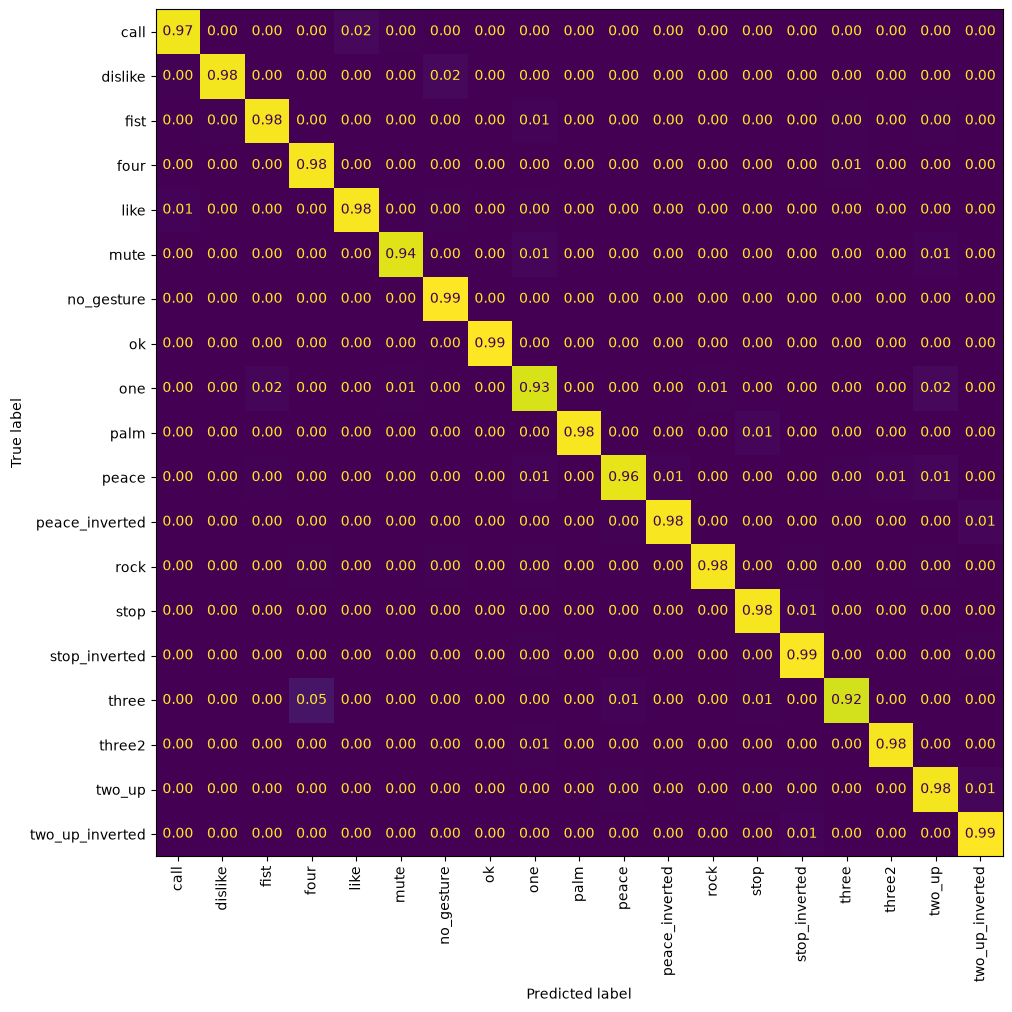

In [8]:
print('Confusion matrix of the MLP on the test set (each row sums to 1)')
fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay(confusion_matrix(y[test_idx], test_pred['MLP'], normalize='true'), display_labels=classes).plot(ax=ax, values_format='.2f', colorbar=False, xticks_rotation=90)
plt.savefig('../../results/gesture/confusion_matrix.png', bbox_inches='tight')
plt.show()

In [9]:
print('Per-gesture results of the MLP')
print(classification_report(y[test_idx], test_pred['MLP'], target_names=classes, digits=3))

Per-gesture results of the MLP
                 precision    recall  f1-score   support

           call      0.986     0.973     0.980       222
        dislike      0.984     0.976     0.980       248
           fist      0.966     0.979     0.972       234
           four      0.940     0.978     0.958       270
           like      0.967     0.983     0.975       237
           mute      0.985     0.944     0.964       270
     no_gesture      0.986     0.991     0.988       776
             ok      1.000     0.993     0.996       281
            one      0.952     0.931     0.942       277
           palm      0.993     0.982     0.987       281
          peace      0.980     0.957     0.968       255
 peace_inverted      0.987     0.983     0.985       238
           rock      0.980     0.980     0.980       255
           stop      0.963     0.981     0.972       265
  stop_inverted      0.961     0.988     0.974       251
          three      0.977     0.923     0.949       274

In [10]:
print('Exporting the MLP for the app as gesture.pt')
torch.save({'state_dict': {k: v.cpu() for k, v in mlp.state_dict().items()}, 'classes': classes}, 'gesture.pt')
print('Saved gesture.pt:', round(os.path.getsize('gesture.pt') / 1e3), 'KB')

Exporting the MLP for the app as gesture.pt
Saved gesture.pt: 218 KB
